Importing libraries

In [ ]:
import requests
import yaml

import pandas as pd
import matplotlib.dates as mdates
import matplotlib.pyplot as plt

from datetime import date



### Task 1
We start by code to fetch the data from [website] using code curtousy of https://frost.met.no/python_example.html

Data retrieved from frost.met.no!


<function matplotlib.pyplot.show(close=None, block=None)>

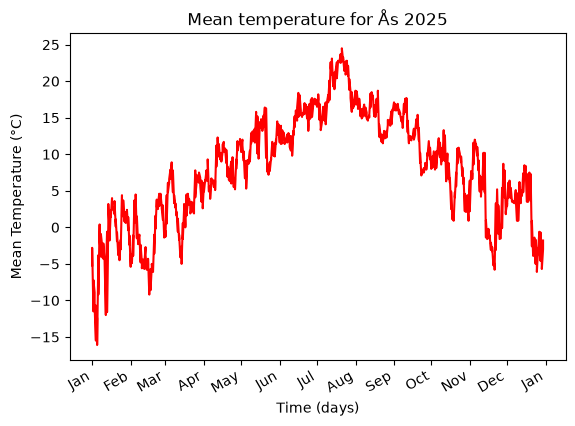

In [51]:
# Insert your own client ID here from a yaml file containing client_ID: <YOUR CLIENT ID>
with open("key.yaml", "r") as f:
    config = yaml.safe_load(f)


# making a function to request data from frost.met.no
# using code example from https://frost.met.no/python_example.html
def get_data(station_id: str, requested_data: str, referencetime: str) -> dict:
    """
    Requests a datatype for the weather station SN17850 in ås for a given referencetime
    from https://frost.met.no/observations/v0.jsonld.

    ARGS:
        requested_data: requested_data: the data that will be requested. Full list of
        available data elements that can be requested at https://frost.met.no/elementtable.

        referencetime: the referencetime for the requested data given as dates given in the format
        2025-01-01/2025-12-31 for data from January 1st 2025 to December 31st 2025.

        station_id: the stations that the requested data should be from
    Returns:
        a requested data in the form of a dictionary
    """

    # set client ID
    client_id = config.get("client_ID")

    # data endpoint and parameters for fetch request
    endpoint = 'https://frost.met.no/observations/v0.jsonld'
    parameters = {
    'sources': station_id,
    'elements': requested_data,
    'referencetime': referencetime,
    }
    # Issue an HTTP GET request
    r = requests.get(endpoint, parameters, auth=(client_id, ''))
    # Extract JSON data
    json = r.json()

    # verifies if data is retrived
    if r.status_code == 200:
        data = json['data']
        print('Data retrieved from frost.met.no!')
    else:
        print('Error! Returned status code %s' % r.status_code)
        print('Message: %s' % json['error']['message'])
        print('Reason: %s' % json['error']['reason'])

    return data


# get data for mean air temperature in 2025 in Ås
data_mean = get_data('SN17850', 'mean(air_temperature P1D)', '2025-01-01/2025-12-31')

# This will return a Dataframe with all of the observations in a table format
df_mean = pd.DataFrame()
for i in range(len(data_mean)):
    row = pd.DataFrame(data_mean[i]['observations'])
    row['referenceTime'] = data_mean[i]['referenceTime']
    row['sourceId'] = data_mean[i]['sourceId']
    df_mean = pd.concat([df_mean, row], ignore_index=True)  # changed pd.append deprecated

df_mean = df_mean.reset_index()

# df_mean.head()

# construct a plot for the data with labeled axis
fig, ax = plt.subplots()
plt.plot(df_mean["referenceTime"], df_mean["value"], color="red")

# adding month labels to the x axis
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
fig.autofmt_xdate()

# adding title and labels and showing the plot
plt.xlabel("Time (days)")
plt.ylabel("Mean Temperature (°C)")
plt.title("Mean temperature for Ås 2025")
plt.show



In [ ]:
# create a function for displaying a summary table for the data from met.no
def generate_summary_table(data: str | pd.DataFrame, data_name: str) -> None:
    """
    Makes a formatted summary table containing mean, median, max, min temperature
    """
    mean_temp = data["value"].mean()
    median_temp = data["value"].median()
    max_temp = data["value"].max()
    min_temp = data["value"].min()

    print(f"--- Summary for: {data_name} ---")
    print(f"{"Mean temperature":<20} {":":^1} {mean_temp:>10.2f}")
    print(f"{"Median temperature":<20} {":":^1} {median_temp:>10.2f}")
    print(f"{"Max temperature":<20} {":":^1} {max_temp:>10.2f}")
    print(f"{"Min temperature":<20} {":":^1} {min_temp:>10.2f}")

# display table for Mean air temperature in Ås 2025
generate_summary_table(df_mean, "Mean air temperature Ås 2025")

--- Summary for Mean temperature Ås 2025 ---
Mean temperature     :       7.90
Median temperature   :       8.35
Max temperature      :      24.50
Min temperature      :     -16.10


### Task 2

In [ ]:
# code here

### Task 3

In [ ]:
# code here

### Task 4 

In [19]:
# code here
def count_heatwaves(station_id: str, station_name: str, start_and_end_date: str) -> int:
    """Collects data from frost.met.no and count the number of heatwaves in a year.
    Generates a summary yml-file.

    Args:
        station_id: ID of which wather station to collect data from.
        station_name: Name of the wather station.
        start_and_end_date: Start and end date to collect data from (YYYY-MM-DD/YYYY-MM-DD).
    Returns:
        count_heatwaves: Number of heatwaves in the given time period.
    """

    # get data for max air temperature
    data_max = get_data(station_id, 'max(air_temperature P1D)', start_and_end_date)

    # Extract dates and max temperatures from list with data
    dates = []
    max_temperatures = []

    for day in data_max:
        date = day['referenceTime']

        for observation in day['observations']:
            if observation['timeOffset'] == 'PT0H':
                max_temperature = observation['value']

                dates.append(date[:10])
                max_temperatures.append(max_temperature)

                break

    # Find all heatwaves and add the affected dates to a list
    heatwaves = []
    start_date = None
    end_date = None
    consecutive_days = 0
    count_heatwaves = 0

    for current_date, temperature in zip(dates, max_temperatures):
        if temperature >= 27:
            if consecutive_days == 0:
                start_date = current_date

            consecutive_days += 1

        else:
            if consecutive_days >= 5:
                heatwaves.append(f'{start_date} - {end_date}')
                count_heatwaves += 1

            consecutive_days = 0
            start_date = None

        end_date = current_date

    # Make a summary, formatted as the example file
    summary = {
        'dates': heatwaves,
        'station_ID': station_id,
        'station_name': station_name,
        'year': start_and_end_date.split('/')[0].split('-')[0],
    }

    # Make a yaml-file with the summary
    with open('heatwave_summary.yml', 'w') as file:
        yaml.dump(summary, file)

    return count_heatwaves


count_heatwaves('SN17850', 'ÅS', '2025-01-01/2025-12-31')

Data retrieved from frost.met.no!


1

### Task 5

In [ ]:
# code here